
# DAY 4: 
-  Tokenization
-  Tokenizing with code

In [3]:
import tiktoken
encoding = tiktoken.encoding_for_model("gpt-4.1-mini")

tokens = encoding.encode("Hi there, My name is Abdullah!")


In [19]:
for i,token_num in enumerate(tokens, start=1):
    print(i, "=",token_num)
        

1 = 12194
2 = 1354
3 = 11
4 = 3673
5 = 1308
6 = 382
7 = 137921
8 = 0


In [ ]:
for token_id in tokens:
    token_text= encoding.decode([token_id])
    print(f"{token_id} = {token_text}" )
    print()

12194 = Hi
1354 =  there
11 = ,
3673 =  My
1308 =  name
382 =  is
137921 =  Abdullah
0 = !


In [20]:
encoding.decode([11])

','

# Another Topic
Illusion of "Memory"

1. checking api key!

In [23]:
import os
from dotenv import load_dotenv

load_dotenv()
api_key= os.getenv("OPENAI_API_KEY")
if not api_key:
    print("No api key found!")
elif  not api_key.startswith("sk-proj-"):
    print("invalid api key!")
else:
    print("Api key found!")

Api key found!


# Open AI lightweight library,
2. for making an api request using HTTP end point

In [26]:
from openai import OpenAI
openai =OpenAI()

We are sending a message request to OpenAI as list of dict
- it is the standard

- messages = [
    {
        "role": "system",
        "content": "Instructions for how the LLM should behave."
    },
    {
        "role": "user",
        "content": "The question or task you want to send to the LLM."
    }
]


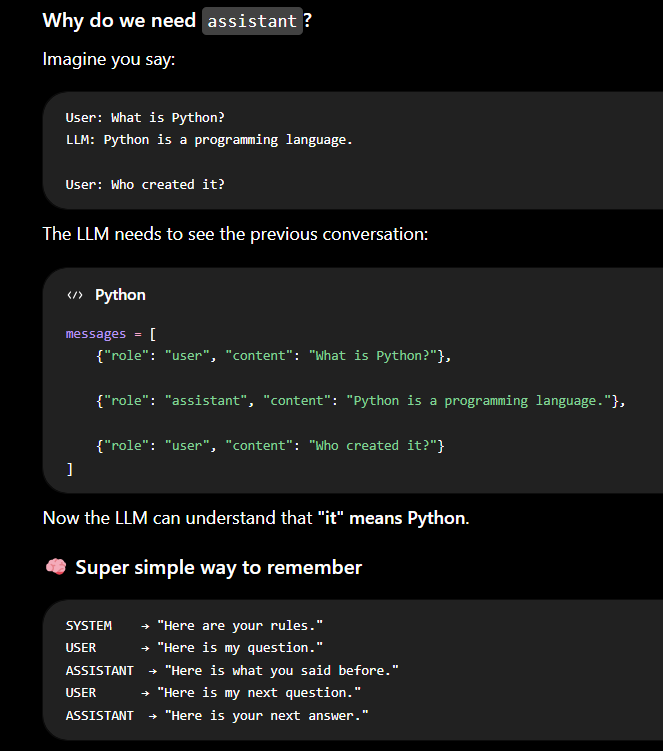

# Ignore the Assistant, 3rd role in the messages! 

In [28]:
messages=[{
    "role": "system", "content": "You are a helpful assistant"
},
          {"role": "user", "content":"Hi, My name is Abdullah!"}]


- for readable output!

In [30]:
response=  openai.chat.completions.create(
    model="gpt-4.1-mini", messages=messages
)
response.choices[0].message.content

'Hello Abdullah! How can I assist you today?'

I have told the model his name,and he replied with my name, so now gonna ask the name, what's my name?

In [ ]:
messages = [
    {"role": "system", "content": "You are a helpful assistant"},
    {"role": "user", "content": "Hi, what's my name?"},
]

response = openai.chat.completions.create(model="gpt-4.1-mini", messages=messages)

response.choices[0].message.content

"Hello! I don't have access to your name. Could you please tell me your name?"

See, I have told him my name but still he is asking me,

Here's what exactly happened..
Yes — for your notes, you can write it like this:

### Why does the LLM ask my name again?

Even if I told the LLM my name earlier, it may ask again if my previous conversation or information is **not included in the messages/context sent to the model**.

An LLM does not automatically remember everything from previous conversations.

For example:

```python
messages = [
    {"role": "user", "content": "My name is Abdullah."},
    {"role": "assistant", "content": "Nice to meet you, Abdullah!"},

    {"role": "user", "content": "What is my name?"}
]
```

Here, the LLM can see the previous messages, so it can answer:

```text
Your name is Abdullah.
```

But if we only send:

```python
messages = [
    {"role": "user", "content": "What is my name?"}
]
```

the model has no information telling it your name, so it may ask:

```text
What is your name?
```

### Key idea

**LLM → only knows the information that is available in its current context.**

Previous conversation → included in context → can use it
Previous conversation → not included → may not know it

This is why applications often keep a **conversation history** and send relevant previous messages along with the new question.


In [38]:
# here we are giving the model history as well!

messages=[{
    "role": "system", "content": "You are a helpful assistant"
},
          {"role": "user", "content":"Hi, My name is Abdullah!"},
          
    {"role": "assistant", "content": "Hello Abdullah! How can I assist you today?"}]

response= openai.chat.completions.create(
    model = "gpt-4.1-mini",
    messages=messages
)
response.choices[0].message.content

'Hi Abdullah! Nice to meet you. How can I help you today?'

See we can ask a follow up questions, If we add an assisted {"key": "value"} ->{"assistant","(previouse answer from the model wkithout brackets)"}
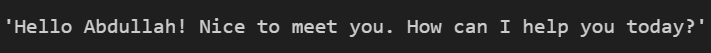